# Temperaturas máximas diárias e percentil 95

A série horária é agregada pela maior temperatura observada em cada dia. Em seguida, calcula-se o percentil 95 da série de máximas diárias.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Leitura da série horária de 1995--2024 e do arquivo bruto de 2025
arquivo_historico = Path("series_temporais_csv/temperatura_ar_1995_2024.csv")
arquivo_2025 = Path(
    "dado_bruto/56_Ana Carolina de Oliveira Rodrigues/"
    "temperatura_ar_horario_max_min/2025.xls"
)
temperatura_historica = pd.read_csv(arquivo_historico, parse_dates=["data_hora"])

MESES_2025 = {
    "JAN": 1, "FEV": 2, "MAR": 3, "ABR": 4, "MAI": 5, "JUN": 6,
    "JUL": 7, "AGO": 8, "SET": 9, "OUT": 10, "NOV": 11, "DEZ": 12,
}

def ler_mes_2025(aba, mes, arquivo=arquivo_2025):
    """Converte uma aba mensal (hora x dia) do arquivo bruto em série horária."""
    bruto = pd.read_excel(arquivo, sheet_name=aba, header=None)
    linha_dias = bruto.index[
        bruto.iloc[:, 0].astype(str).str.strip().str.upper().eq("H/D")
    ][0]

    dias = pd.to_numeric(bruto.iloc[linha_dias, 1:], errors="coerce")
    horas = pd.to_numeric(bruto.iloc[linha_dias + 1 :, 0], errors="coerce")
    valores = bruto.iloc[linha_dias + 1 :, 1:].copy()
    valores.index = horas
    valores.columns = dias
    valores = valores.loc[valores.index.notna(), valores.columns.notna()]

    tabela = (
        valores.rename_axis(index="hora", columns="dia")
        .reset_index()
        .melt(id_vars="hora", var_name="dia", value_name="valor")
    )
    tabela["hora"] = pd.to_numeric(tabela["hora"], errors="coerce")
    tabela["dia"] = pd.to_numeric(tabela["dia"], errors="coerce")
    tabela["valor"] = pd.to_numeric(tabela["valor"], errors="coerce")
    tabela = tabela.dropna(subset=["hora", "dia"])
    tabela = tabela[tabela["hora"].between(1, 24)]

    ultimo_dia = pd.Period(year=2025, month=mes, freq="M").days_in_month
    tabela = tabela[tabela["dia"].between(1, ultimo_dia)]
    tabela["data_hora"] = (
        pd.to_datetime({"year": 2025, "month": mes, "day": tabela["dia"].astype(int)})
        + pd.to_timedelta(tabela["hora"] - 1, unit="h")
    )
    return tabela[["data_hora", "valor"]]

temperatura_2025 = pd.concat(
    [ler_mes_2025(aba, mes) for aba, mes in MESES_2025.items()],
    ignore_index=True,
).sort_values("data_hora")

temperatura = pd.concat([temperatura_historica, temperatura_2025], ignore_index=True)
# Remove horários duplicados e trata -99 como dado ausente.
temperatura = temperatura.drop_duplicates(subset="data_hora", keep="first")
temperatura["valor"] = temperatura["valor"].replace(-99, pd.NA)

# Máxima de cada dia e percentil 95 das máximas diárias
temperaturas_maximas_diarias = (
    temperatura.set_index("data_hora")["valor"]
    .resample("D")
    .max()
    .rename("temperatura_maxima_diaria")
)
percentil_95 = temperaturas_maximas_diarias.quantile(0.95)

print(f"Período analisado: {temperaturas_maximas_diarias.index.min():%d/%m/%Y} a {temperaturas_maximas_diarias.index.max():%d/%m/%Y}")
print(f"Dias com máxima calculada: {temperaturas_maximas_diarias.notna().sum():,}")
print(f"Percentil 95 das temperaturas máximas diárias: {percentil_95:.1f} °C")

temperaturas_maximas_diarias.to_frame().head()

Período analisado: 01/01/1995 a 31/12/2025
Dias com máxima calculada: 11,323
Percentil 95 das temperaturas máximas diárias: 31.8 °C


,temperatura_maxima_diaria
data_hora,
1995-01-01,25.2
1995-01-02,28.3
1995-01-03,24.3
1995-01-04,26.6
1995-01-05,29.2


## Frequência de intervalos quentes

Um intervalo quente é definido como uma sequência de **três ou mais dias consecutivos** cuja temperatura máxima diária é **maior que o percentil 95**. Cada intervalo é contado uma única vez, no mês em que se inicia.

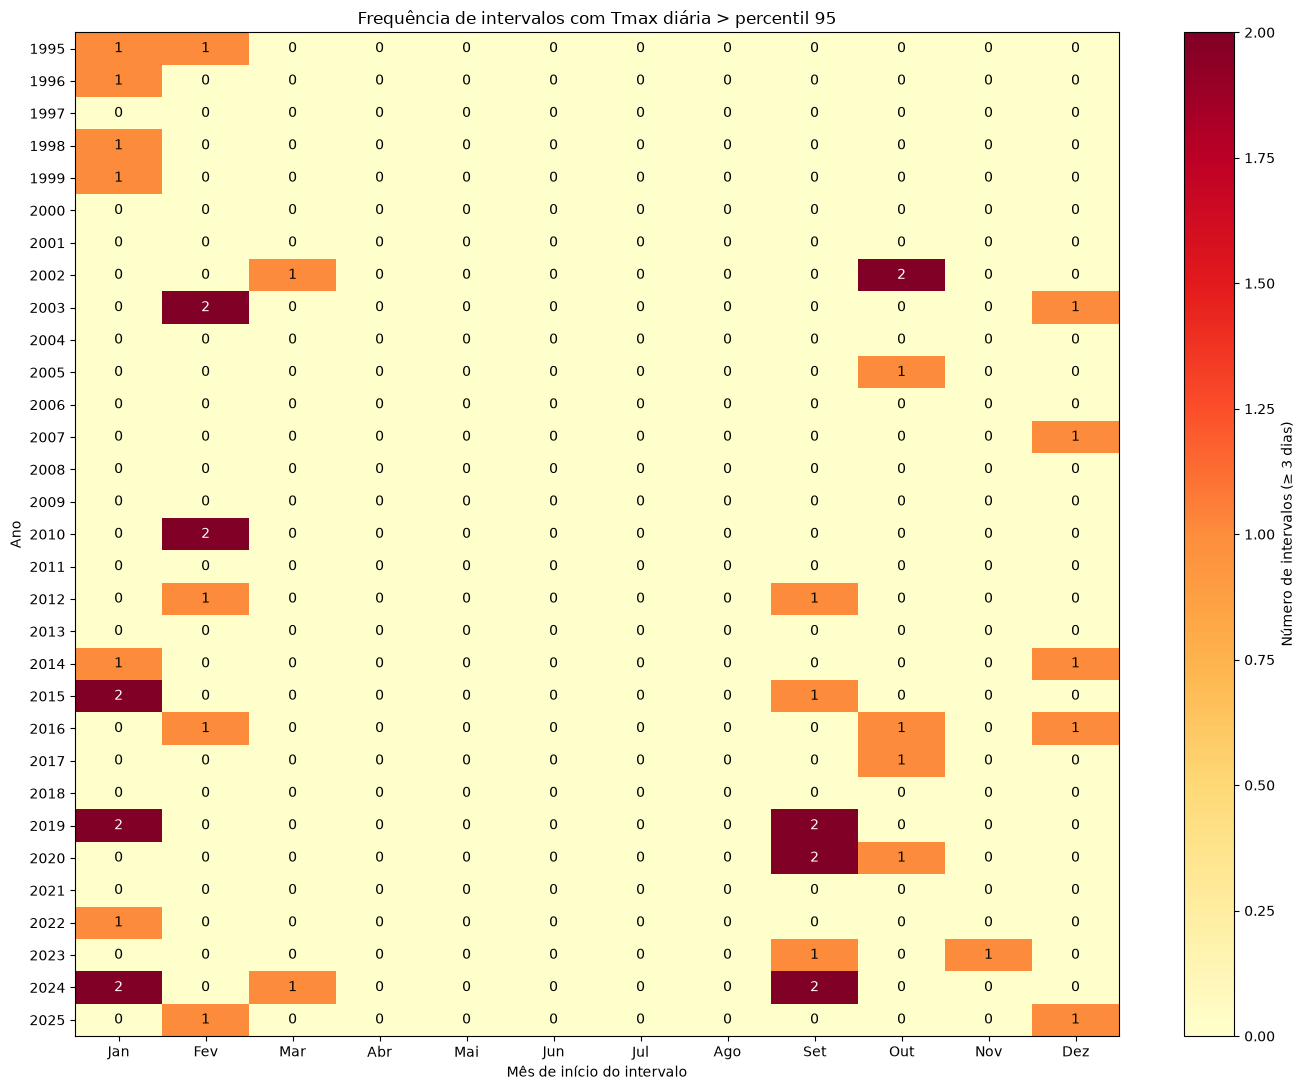

Intervalos de pelo menos 3 dias encontrados: 43


,grupo,inicio,fim,duracao_dias,maxima_no_evento,ano,mes
0,2,1995-01-15,1995-01-17,3,33.5,1995,1
2,6,1995-02-23,1995-02-25,3,33.5,1995,2
11,24,1996-01-25,1996-01-28,4,34.0,1996,1
29,60,1998-01-30,1998-02-01,3,33.0,1998,1
38,78,1999-01-19,1999-01-21,3,35.1,1999,1
57,116,2002-03-07,2002-03-09,3,32.4,2002,3
59,120,2002-10-06,2002-10-12,7,35.0,2002,10
60,122,2002-10-14,2002-10-16,3,34.1,2002,10
73,148,2003-02-08,2003-02-12,5,33.4,2003,2
74,150,2003-02-25,2003-03-03,7,33.5,2003,2


In [6]:
# Identifica sequências consecutivas de dias acima do percentil 95
serie_diaria = temperaturas_maximas_diarias.rename_axis("data").reset_index()
serie_diaria["acima_p95"] = serie_diaria["temperatura_maxima_diaria"] > percentil_95
serie_diaria["grupo"] = (
    serie_diaria["acima_p95"]
    .ne(serie_diaria["acima_p95"].shift())
    .cumsum()
)

eventos = (
    serie_diaria.loc[serie_diaria["acima_p95"]]
    .groupby("grupo", as_index=False)
    .agg(
        inicio=("data", "min"),
        fim=("data", "max"),
        duracao_dias=("data", "size"),
        maxima_no_evento=("temperatura_maxima_diaria", "max"),
    )
    .query("duracao_dias >= 3")
)

# A frequência é atribuída ao ano e ao mês de início de cada intervalo.
eventos["ano"] = eventos["inicio"].dt.year
eventos["mes"] = eventos["inicio"].dt.month

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
frequencia_eventos = (
    eventos.pivot_table(
        index="ano", columns="mes", values="grupo", aggfunc="count", fill_value=0
    )
    .reindex(index=range(temperatura["data_hora"].dt.year.min(),
                         temperatura["data_hora"].dt.year.max() + 1),
             columns=range(1, 13), fill_value=0)
)
frequencia_eventos.columns = meses

fig, ax = plt.subplots(figsize=(14, 11))
imagem = ax.imshow(frequencia_eventos, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(12), meses)
ax.set_yticks(range(len(frequencia_eventos.index)), frequencia_eventos.index)
ax.set_title("Frequência de intervalos com Tmax diária > percentil 95")
ax.set_xlabel("Mês de início do intervalo")
ax.set_ylabel("Ano")

# Mostra a contagem em cada célula do heatmap.
for linha, ano in enumerate(frequencia_eventos.index):
    for coluna, mes in enumerate(frequencia_eventos.columns):
        quantidade = frequencia_eventos.loc[ano, mes]
        cor_texto = "white" if quantidade > frequencia_eventos.to_numpy().max() / 2 else "black"
        ax.text(coluna, linha, int(quantidade), ha="center", va="center", color=cor_texto)

fig.colorbar(imagem, ax=ax, label="Número de intervalos (≥ 3 dias)")
fig.tight_layout()
plt.show()

print(f"Intervalos de pelo menos 3 dias encontrados: {len(eventos)}")
eventos

## Eventos simultâneos de temperatura do ar e bulbo úmido

Um evento simultâneo ocorre quando, em cada dia de uma sequência de **três ou mais dias consecutivos**, a temperatura máxima diária do ar e a máxima diária de bulbo úmido são ambas maiores que seus respectivos percentis 95. Cada evento é contabilizado no mês em que começa.

In [ ]:
# Carrega a série de bulbo úmido no mesmo período (1995--2025).
arquivo_bulbo_historico = Path("series_temporais_csv/temperatura_bulbo_umido_1995_2024.csv")
arquivo_bulbo_2025 = Path(
    "dado_bruto/56_Ana Carolina de Oliveira Rodrigues/"
    "tempbulboumido/2025.xls"
)
bulbo_umido_historico = pd.read_csv(arquivo_bulbo_historico, parse_dates=["data_hora"])

def ler_mes_bulbo_2025(aba, mes):
    """Converte uma aba mensal de bulbo úmido em série horária."""
    bruto = pd.read_excel(arquivo_bulbo_2025, sheet_name=aba, header=None)
    linha_dias = bruto.index[
        bruto.iloc[:, 0].astype(str).str.strip().str.upper().eq("H/D")
    ][0]

    dias = pd.to_numeric(bruto.iloc[linha_dias, 1:], errors="coerce")
    horas = pd.to_numeric(bruto.iloc[linha_dias + 1 :, 0], errors="coerce")
    valores = bruto.iloc[linha_dias + 1 :, 1:].copy()
    valores.index = horas
    valores.columns = dias
    valores = valores.loc[valores.index.notna(), valores.columns.notna()]

    tabela = (
        valores.rename_axis(index="hora", columns="dia")
        .reset_index()
        .melt(id_vars="hora", var_name="dia", value_name="valor")
    )
    tabela["hora"] = pd.to_numeric(tabela["hora"], errors="coerce")
    tabela["dia"] = pd.to_numeric(tabela["dia"], errors="coerce")
    tabela["valor"] = pd.to_numeric(tabela["valor"], errors="coerce")
    tabela = tabela.dropna(subset=["hora", "dia"])
    tabela = tabela[tabela["hora"].between(1, 24)]
    ultimo_dia = pd.Period(year=2025, month=mes, freq="M").days_in_month
    tabela = tabela[tabela["dia"].between(1, ultimo_dia)]
    tabela["data_hora"] = (
        pd.to_datetime({"year": 2025, "month": mes, "day": tabela["dia"].astype(int)})
        + pd.to_timedelta(tabela["hora"] - 1, unit="h")
    )
    return tabela[["data_hora", "valor"]]
bulbo_umido_2025 = pd.concat(
    [ler_mes_bulbo_2025(aba, mes) for aba, mes in MESES_2025.items()],
    ignore_index=True,
).sort_values("data_hora")

bulbo_umido = pd.concat([bulbo_umido_historico, bulbo_umido_2025], ignore_index=True)
bulbo_umido = bulbo_umido.drop_duplicates(subset="data_hora", keep="first")
bulbo_umido["valor"] = bulbo_umido["valor"].mask(bulbo_umido["valor"].eq(-99))
temperaturas_bulbo_umido_maximas_diarias = (
    bulbo_umido.set_index("data_hora")["valor"]
    .resample("D")
    .max()
    .rename("temperatura_bulbo_umido_maxima_diaria")
)
percentil_95_bulbo_umido = temperaturas_bulbo_umido_maximas_diarias.quantile(0.95)

# Um dia só é classificado como simultâneo quando as duas condições são atendidas.
diarias_conjuntas = pd.concat(
    [temperaturas_maximas_diarias, temperaturas_bulbo_umido_maximas_diarias], axis=1
).dropna()
diarias_conjuntas["acima_dos_dois_p95"] = (
    (diarias_conjuntas["temperatura_maxima_diaria"] > percentil_95)
    & (
        diarias_conjuntas["temperatura_bulbo_umido_maxima_diaria"]
        > percentil_95_bulbo_umido
    )
)
diarias_conjuntas["grupo"] = (
    diarias_conjuntas["acima_dos_dois_p95"]
    .ne(diarias_conjuntas["acima_dos_dois_p95"].shift())
    .cumsum()
)

eventos_simultaneos = (
    diarias_conjuntas.loc[diarias_conjuntas["acima_dos_dois_p95"]]
    .reset_index(names="data")
    .groupby("grupo", as_index=False)
    .agg(
        inicio=("data", "min"),
        fim=("data", "max"),
        duracao_dias=("data", "size"),
        maxima_temperatura_ar=("temperatura_maxima_diaria", "max"),
        maxima_bulbo_umido=("temperatura_bulbo_umido_maxima_diaria", "max"),
    )
    .query("duracao_dias >= 3")
)
eventos_simultaneos["ano"] = eventos_simultaneos["inicio"].dt.year
eventos_simultaneos["mes"] = eventos_simultaneos["inicio"].dt.month

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
frequencia_eventos_simultaneos = (
    eventos_simultaneos.pivot_table(
        index="ano", columns="mes", values="duracao_dias", aggfunc="count", fill_value=0
    )
    .reindex(
        index=range(diarias_conjuntas.index.year.min(), diarias_conjuntas.index.year.max() + 1),
        columns=range(1, 13),
        fill_value=0,
    )
)
frequencia_eventos_simultaneos.columns = meses

fig, ax = plt.subplots(figsize=(14, 11))
imagem = ax.imshow(frequencia_eventos_simultaneos, cmap="PuRd", aspect="auto")
ax.set_xticks(range(12), meses)
ax.set_yticks(range(len(frequencia_eventos_simultaneos.index)), frequencia_eventos_simultaneos.index)
ax.set_title("Frequência de eventos simultâneos acima dos percentis 95")
ax.set_xlabel("Mês de início do evento")
ax.set_ylabel("Ano")

valor_maximo = frequencia_eventos_simultaneos.to_numpy().max()
for linha, ano in enumerate(frequencia_eventos_simultaneos.index):
    for coluna, mes in enumerate(frequencia_eventos_simultaneos.columns):
        quantidade = frequencia_eventos_simultaneos.loc[ano, mes]
        cor_texto = "white" if quantidade > valor_maximo / 2 else "black"
        ax.text(coluna, linha, int(quantidade), ha="center", va="center", color=cor_texto)

fig.colorbar(imagem, ax=ax, label="Número de eventos simultâneos (≥ 3 dias)")
fig.tight_layout()
plt.show()

print(f"P95 da temperatura máxima diária: {percentil_95:.1f} °C")
print(f"P95 do bulbo úmido máximo diário: {percentil_95_bulbo_umido:.1f} °C")
print(f"Eventos simultâneos de pelo menos 3 dias: {len(eventos_simultaneos)}")
eventos_simultaneos